# 03 — Machine learning: XGBoost and LSTM

This notebook examines XGBoost and LSTM results alongside the econometric baselines. XGBoost is compared with and without VIX features. The optional LSTM uses a 22-session input sequence, 32 hidden units, dropout of 0.15, Adam and validation early stopping (maximum 25 epochs, patience 7).

The model fitting is performed by `run_pipeline.py` (XGBoost) and `scripts/run_lstm_extension.py` (LSTM). This notebook reads the saved out-of-sample forecasts and metrics so that the analysis is lightweight and reproducible.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / 'outputs' / 'forecast_metrics.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / 'outputs'
metrics = pd.read_csv(OUT / 'forecast_metrics.csv')
ml_models = ['XGBoost_no_VIX','XGBoost_with_VIX','LSTM','GARCH_1_1','HAR_RV_with_VIX']
for h in (1, 5, 21):
    print(f'{h}-session forecasts')
    display(metrics[(metrics.horizon == h) & metrics.model.isin(ml_models)].sort_values('qlike')[['model','n','qlike','rmse_vol','mae_vol']])

1-session forecasts


,model,n,qlike,rmse_vol,mae_vol
0,HAR_RV_with_VIX,2448,-2.919566,0.122392,0.088553
1,LSTM,2448,-2.887011,0.132068,0.095753
4,XGBoost_with_VIX,2448,-2.857553,0.136646,0.101683
5,XGBoost_no_VIX,2448,-2.847775,0.129966,0.094734
6,GARCH_1_1,2448,-2.815626,0.129498,0.093628


5-session forecasts


,model,n,qlike,rmse_vol,mae_vol
10,XGBoost_with_VIX,2444,-2.841403,0.076224,0.052308
11,HAR_RV_with_VIX,2444,-2.836309,0.078510,0.050711
12,LSTM,2444,-2.818578,0.084114,0.057262
13,XGBoost_no_VIX,2444,-2.813703,0.079716,0.053984
16,GARCH_1_1,2444,-2.758436,0.087657,0.057101


21-session forecasts


,model,n,qlike,rmse_vol,mae_vol
20,XGBoost_with_VIX,2428,-2.559989,0.086346,0.055033
22,LSTM,2428,-2.542599,0.088820,0.052530
24,GARCH_1_1,2428,-2.540387,0.089445,0.053150
25,HAR_RV_with_VIX,2428,-2.539589,0.084204,0.049567
26,XGBoost_no_VIX,2428,-2.519663,0.087539,0.054559


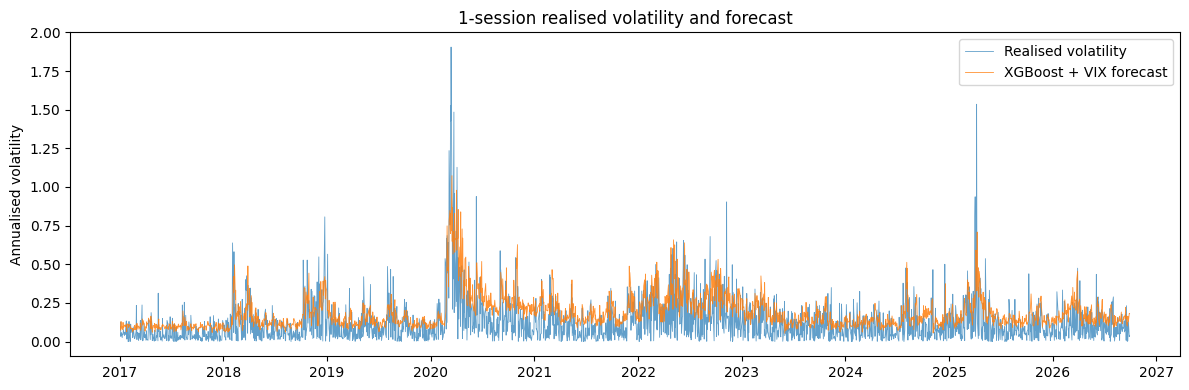

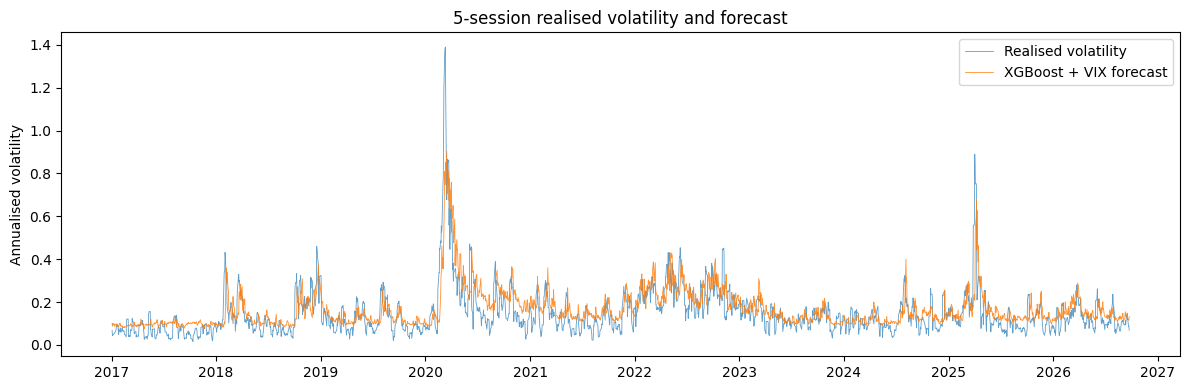

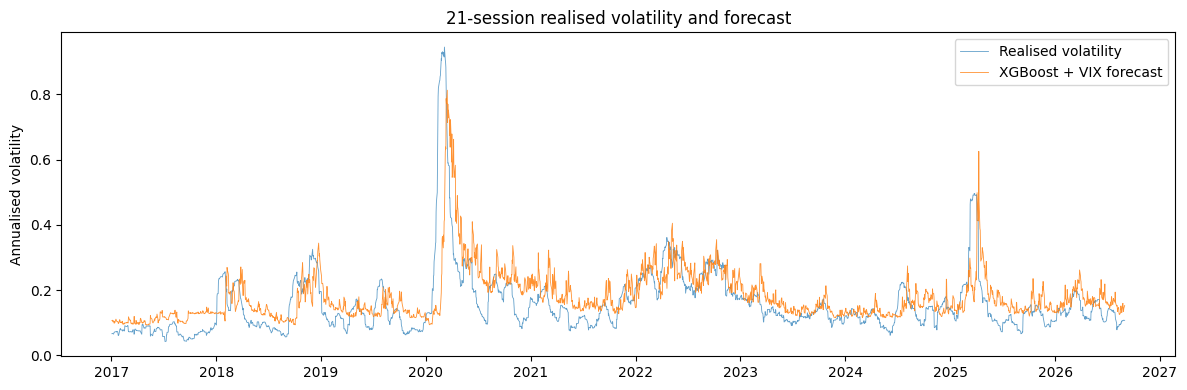

In [2]:
# Inspect model predictions against realised forward volatility for the test period.
forecasts = pd.read_csv(OUT / 'out_of_sample_forecasts.csv', parse_dates=['date'], low_memory=False)
for h in (1, 5, 21):
    sub = forecasts[(forecasts.horizon == h) & forecasts.model.isin(['XGBoost_with_VIX','LSTM','HAR_RV_with_VIX'])].copy()
    if sub.empty:
        continue
    sub['forecast_vol'] = sub['forecast_variance'].clip(lower=0) ** 0.5
    sub['realised_vol'] = sub['realised_variance'].clip(lower=0) ** 0.5
    fig, ax = plt.subplots(figsize=(12, 4))
    sample = sub[sub.model == 'XGBoost_with_VIX']
    if not sample.empty:
        ax.plot(sample.date, sample.realised_vol, lw=0.6, alpha=0.7, label='Realised volatility')
        ax.plot(sample.date, sample.forecast_vol, lw=0.6, alpha=0.85, label='XGBoost + VIX forecast')
    ax.set(title=f'{h}-session realised volatility and forecast', ylabel='Annualised volatility')
    ax.legend()
    plt.tight_layout()
    plt.show()

## What the results say

XGBoost + VIX leads by QLIKE at five and 21 sessions, while HAR + VIX is strongest at one session. LSTM is competitive but does not lead any of the three horizons. The LSTM is included as a meaningful deep-learning benchmark, not as a pre-assumed improvement.

Compare VIX-inclusive and VIX-excluded model variants in `outputs/vix_ablation_dm_tests.csv`; statistical significance is assessed after Holm correction.